# First Classification Model Pipeline

#### Proposed pipeline
`EMG + IMU → preprocessing → bilateral movement-state generation → state classification → bilateral transition validation → accepted motor state`

The data contains:
- 8 EMG channels
- 6 IMUs (left/right thigh, shank, foot)
- each IMU has Accel X/Y/Z and Gyro X/Y/Z
- standing baseline + five-step walking trial

### 1. Load the Libraries

In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


### 2. Load the Data

In [20]:

from pathlib import Path

DATA_FILES = {
    "Walking": "Leen_walking_processed.csv",
    "Standing": "Leen_standing_processed.csv",
    "Elevate": "Leen_elevate_processed.csv",
    "Forward": "Leen_walking_forward_processed.csv",
}

# Locate the Leen folder
base = Path.cwd()

if (base / "Data" / "Leen").is_dir():
    data_folder = base / "Data" / "Leen"
elif (base / "Leen").is_dir():
    data_folder = base / "Leen"
else:
    raise FileNotFoundError(
        f"Cannot find the Leen data folder from {base}"
    )

recordings = {}

for name, filename in DATA_FILES.items():
    path = data_folder / filename

    if not path.is_file():
        print(f"Missing file: {path}")
        continue

    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip()
    recordings[name] = df

    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")


Missing file: c:\Users\leena\FES-Exoskeleton-Project\Data Analysis 2 - Leen\Data\Leen\Leen_walking_processed.csv
Standing: 14999 rows, 80 columns
Elevate: 75319 rows, 80 columns
Forward: 13519 rows, 80 columns


### 3. Identify EMG and IMU columns

In [21]:

# Time column
time_col = "Time_s"

# EMG muscles
muscles = [
    "Multifidus_R", "Multifidus_L",
    "ExternalOblique_R", "ExternalOblique_L",
    "RectusAbdominis_R", "RectusAbdominis_L",
    "ErectorSpinae_R", "ErectorSpinae_L"
]

# Use filtered EMG signals
emg_cols = [f"{muscle}_emg_filtered" for muscle in muscles]

# All 36 IMU measurements
imu_cols = [
    f"{location}_{side}_{signal}_{axis}"
    for side in ["L", "R"]
    for location in ["Thigh", "Shank", "Foot"]
    for signal in ["Accel", "Gyro"]
    for axis in ["X", "Y", "Z"]
]

required_cols = [time_col] + emg_cols + imu_cols

# Verify columns
for name, df in recordings.items():
    missing = set(required_cols) - set(df.columns)

    if missing:
        raise ValueError(f"{name} missing columns: {missing}")

print("EMG channels:", len(emg_cols))
print("IMU channels:", len(imu_cols))
print("Total required columns:", len(required_cols))


EMG channels: 8
IMU channels: 36
Total required columns: 45


### 4. Clean and validate the data

In [22]:

clean_recordings = {}

for name, df in recordings.items():
    df = df[required_cols].copy()

    # Convert columns to numeric
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan)

    # Remove rows with missing measurements
    df = df.dropna().reset_index(drop=True)

    # Require increasing timestamps
    df = df.loc[df[time_col].diff().fillna(1) > 0]
    df = df.reset_index(drop=True)

    if len(df) < 3:
        raise ValueError(f"{name}: insufficient valid samples")

    # Estimate sampling frequency
    dt = df[time_col].diff().dropna()
    fs = 1 / dt.median()

    clean_recordings[name] = (df, fs)

    print(f"{name}: {len(df)} valid samples")
    print(f"Estimated sampling rate: {fs:.2f} Hz")


Standing: 14990 valid samples
Estimated sampling rate: 2000.36 Hz
Elevate: 75311 valid samples
Estimated sampling rate: 2000.36 Hz
Forward: 13511 valid samples
Estimated sampling rate: 2000.36 Hz


### SECTION 5–6: Windowing, features, and data splitting

In [23]:

# SECTION 5–6: Windowing, features, and data splitting

WINDOW_MS = 500
TARGET_MS = 100
STEP_MS = 100

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

feature_names = ["MAV", "RMS", "STD", "WL"]
feature_cols = [
    f"{col}_{feature}"
    for col in emg_cols
    for feature in feature_names
]

def extract_emg_features(x):
    mav = np.mean(np.abs(x), axis=0)
    rms = np.sqrt(np.mean(x ** 2, axis=0))
    std = np.std(x, axis=0)
    wl = np.mean(np.abs(np.diff(x, axis=0)), axis=0)

    return np.column_stack([mav, rms, std, wl]).ravel()


def make_windows(df, fs):
    size = max(2, round(fs * WINDOW_MS / 1000))
    target_size = max(1, round(fs * TARGET_MS / 1000))
    step = max(1, round(fs * STEP_MS / 1000))

    emg = df[emg_cols].to_numpy(dtype=np.float32)
    imu = df[imu_cols].to_numpy(dtype=np.float32)
    times = df[time_col].to_numpy(dtype=float)

    features, targets, sequences, timestamps = [], [], [], []

    for start in range(0, len(df) - size + 1, step):
        end = start + size

        # Reject windows with discontinuous timestamps
        dt = np.diff(times[start:end])
        if np.any(dt <= 0) or np.any(dt > 2.5 / fs):
            continue

        x = emg[start:end]
        y = imu[end - target_size:end].mean(axis=0)

        features.append(extract_emg_features(x))
        targets.append(y)
        sequences.append(x)
        timestamps.append(times[end - 1])

    return (
        np.asarray(features, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(sequences, dtype=np.float32),
        np.asarray(timestamps)
    )


parts = {
    "train": {"X": [], "y": [], "seq": [], "time": []},
    "val": {"X": [], "y": [], "seq": [], "time": []},
    "test": {"X": [], "y": [], "seq": [], "time": []}
}

for name, (df, fs) in clean_recordings.items():
    n = len(df)
    train_end = int(n * TRAIN_RATIO)
    val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

    segments = {
        "train": df.iloc[:train_end],
        "val": df.iloc[train_end:val_end],
        "test": df.iloc[val_end:]
    }

    print(f"\n{name}:")

    for split_name, segment in segments.items():
        X, y, seq, times = make_windows(segment, fs)

        if len(X) == 0:
            raise ValueError(f"{name}: no {split_name} windows")

        parts[split_name]["X"].append(X)
        parts[split_name]["y"].append(y)
        parts[split_name]["seq"].append(seq)
        parts[split_name]["time"].append(times)

        print(f"  {split_name}: {len(X)} windows")


def combine(split_name):
    p = parts[split_name]

    return (
        pd.DataFrame(np.vstack(p["X"]), columns=feature_cols),
        pd.DataFrame(np.vstack(p["y"]), columns=imu_cols),
        np.concatenate(p["seq"]),
        np.concatenate(p["time"])
    )


X_train, y_train, X_train_seq, time_train = combine("train")
X_val, y_val, X_val_seq, time_val = combine("val")
X_test, y_test, X_test_seq, time_test = combine("test")

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("CNN/LSTM shape:", X_train_seq.shape)



Standing:
  train: 48 windows
  val: 7 windows
  test: 7 windows

Elevate:
  train: 259 windows
  val: 52 windows
  test: 52 windows

Forward:
  train: 43 windows
  val: 6 windows
  test: 6 windows

Training: (350, 32)
Validation: (65, 32)
Testing: (65, 32)
CNN/LSTM shape: (350, 1000, 8)


### 7. Train the three regression models

In [24]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=3,
        n_jobs=-1,
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        MultiOutputRegressor(
            SVR(kernel="rbf", C=10, epsilon=0.1),
            n_jobs=-1
        )
    ),

    "Gradient Boosting": MultiOutputRegressor(
        HistGradientBoostingRegressor(
            max_iter=100,
            learning_rate=0.05,
            max_leaf_nodes=15,
            random_state=42
        ),
        n_jobs=-1
    ),

    "Baseline": DummyRegressor(strategy="mean"),

    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )
}

predictions = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

print("Traditional models completed.")



Training Random Forest...
Training SVM...
Training Gradient Boosting...
Training Baseline...
Training Ridge...
Traditional models completed.


In [25]:

# Scale EMG sequences
n_channels = len(emg_cols)

emg_scaler = StandardScaler()

emg_scaler.fit(
    X_train_seq.reshape(-1, n_channels)
)

def scale_sequences(data):
    shape = data.shape

    return emg_scaler.transform(
        data.reshape(-1, n_channels)
    ).reshape(shape).astype(np.float32)


X_train_nn = scale_sequences(X_train_seq)
X_val_nn = scale_sequences(X_val_seq)
X_test_nn = scale_sequences(X_test_seq)

# Scale IMU targets
imu_scaler = StandardScaler()

y_train_nn = imu_scaler.fit_transform(y_train).astype(np.float32)
y_val_nn = imu_scaler.transform(y_val).astype(np.float32)

print("Training:", X_train_nn.shape)
print("Validation:", X_val_nn.shape)
print("Testing:", X_test_nn.shape)


Training: (350, 1000, 8)
Validation: (65, 1000, 8)
Testing: (65, 1000, 8)


In [26]:

def build_cnn(input_shape, output_size):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv1D(32, 7, padding="same", activation="relu"),
        layers.MaxPooling1D(2),

        layers.Conv1D(64, 5, padding="same", activation="relu"),
        layers.MaxPooling1D(2),

        layers.Conv1D(64, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation="relu"),
        layers.Dense(output_size)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="mse"
    )

    return model


cnn = build_cnn(
    X_train_nn.shape[1:],
    len(imu_cols)
)


In [27]:

def build_lstm(input_shape, output_size):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        layers.LSTM(64),
        layers.Dense(64, activation="relu"),
        layers.Dense(output_size)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="mse"
    )

    return model


lstm = build_lstm(
    X_train_nn.shape[1:],
    len(imu_cols)
)


In [28]:

neural_models = {
    "CNN": cnn,
    "LSTM": lstm
}

histories = {}

for name, model in neural_models.items():
    print(f"\nTraining {name}...")

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_nn,
        y_train_nn,
        validation_data=(X_val_nn, y_val_nn),
        epochs=50,
        batch_size=64,
        callbacks=[early_stop],
        shuffle=False,
        verbose=1
    )

    histories[name] = history

    pred_scaled = model.predict(
        X_test_nn,
        verbose=0
    )

    predictions[name] = imu_scaler.inverse_transform(
        pred_scaled
    )

print("\nAll seven models completed.")



Training CNN...
Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - loss: 1.0154WARNING:tensorflow:5 out of the last 57 calls to <function Trainer._make_function.<locals>.one_step_on_data at 0x00000281CC3CBCC0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 594ms/step - loss: 1.0154 - val_loss: 1.1422
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - loss: 0.9995 - val_loss: 1.1363
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - loss: 0.9955

### 8. Evaluate and compare the models

In [29]:

results = []

actual = y_test.to_numpy()

target_scale = y_train.std(axis=0).to_numpy()
target_scale = np.where(target_scale > 1e-12, target_scale, 1.0)

for name, pred in predictions.items():
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    r2 = r2_score(
        actual,
        pred,
        multioutput="raw_values"
    )

    per_channel_rmse = np.sqrt(
        np.mean((actual - pred) ** 2, axis=0)
    )

    nrmse = np.mean(per_channel_rmse / target_scale)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "NRMSE": nrmse,
        "Mean R2": np.mean(r2)
    })

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    "NRMSE"
).reset_index(drop=True)

display(comparison.round(4))


,Model,MAE,RMSE,NRMSE,Mean R2
0,Random Forest,32.1170,64.1926,0.7628,0.1816
1,Gradient Boosting,37.4381,70.0298,0.8169,0.0113
2,CNN,42.6379,78.0059,0.8169,0.1004
3,Ridge,46.7795,81.7136,0.8428,0.0134
4,SVM,49.7673,107.2485,0.8863,0.0201
5,Baseline,71.5151,133.7159,0.9554,-0.0957
6,LSTM,67.2936,126.8690,0.9597,-0.1525


### 9. Evaluate each IMU location separately

In [30]:

location_results = []

for name, pred in predictions.items():
    pred_df = pd.DataFrame(pred, columns=imu_cols)

    for location in ["Thigh", "Shank", "Foot"]:
        for side in ["L", "R"]:
            cols = [
                c for c in imu_cols
                if c.startswith(f"{location}_{side}_")
            ]

            actual = y_test[cols].to_numpy()
            estimated = pred_df[cols].to_numpy()

            location_results.append({
                "Model": name,
                "Location": location,
                "Side": side,
                "R2": r2_score(actual, estimated)
            })

location_comparison = pd.DataFrame(location_results)
display(location_comparison)


,Model,Location,Side,R2
0,Random Forest,Thigh,L,0.499464
1,Random Forest,Thigh,R,0.172811
2,Random Forest,Shank,L,0.178767
3,Random Forest,Shank,R,-0.040741
4,Random Forest,Foot,L,0.208065
5,Random Forest,Foot,R,0.071084
6,SVM,Thigh,L,0.219281
7,SVM,Thigh,R,0.049858
8,SVM,Shank,L,-0.030391
9,SVM,Shank,R,-0.103772


### 10. Visualize actual vs. predicted IMU signals

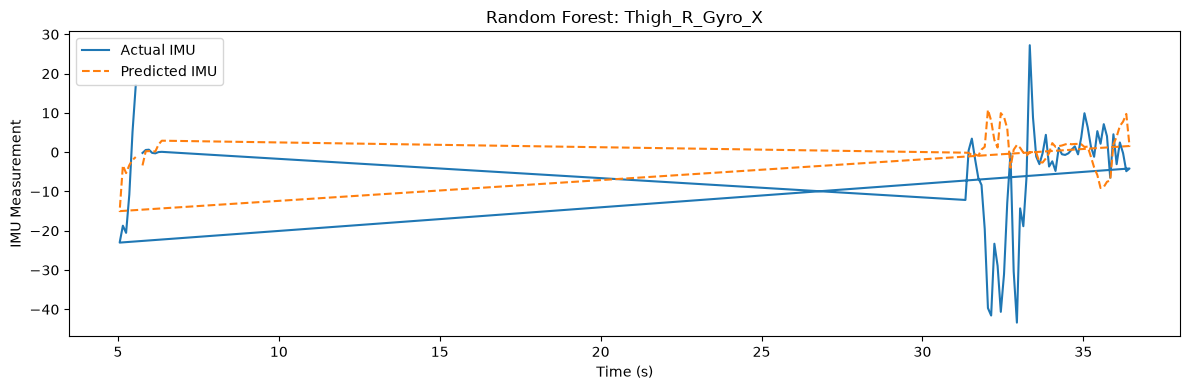

In [31]:

BEST_MODEL = comparison.sort_values("NRMSE").iloc[0]["Model"]

CHANNEL = "Thigh_R_Gyro_X"

actual = y_test[CHANNEL].to_numpy()
pred = pd.DataFrame(
    predictions[BEST_MODEL],
    columns=imu_cols
)[CHANNEL].to_numpy()

plt.figure(figsize=(12, 4))

plt.plot(time_test, actual, label="Actual IMU")
plt.plot(time_test, pred, label="Predicted IMU", linestyle="--")

plt.title(f"{BEST_MODEL}: {CHANNEL}")
plt.xlabel("Time (s)")
plt.ylabel("IMU Measurement")
plt.legend()
plt.tight_layout()
plt.show()


### 11. Predict IMU measurements from new EMG data

In [32]:

BEST_MODEL = comparison.iloc[0]["Model"]

# Display the first prediction from the best model
predicted_imu = pd.DataFrame(
    predictions[BEST_MODEL][:1],
    columns=imu_cols
)

print("Best model:", BEST_MODEL)
display(predicted_imu.T)


Best model: Random Forest


,0
Thigh_L_Accel_X,979.912362
Thigh_L_Accel_Y,23.568001
Thigh_L_Accel_Z,-49.379603
Thigh_L_Gyro_X,-3.672938
Thigh_L_Gyro_Y,-0.840791
Thigh_L_Gyro_Z,-1.428996
Shank_L_Accel_X,977.511182
Shank_L_Accel_Y,-98.143294
Shank_L_Accel_Z,52.736677
Shank_L_Gyro_X,-3.025598
